# E-Commerce Business Analytics — Portfolio Walkthrough
**Andre Mehangga Kurniawan | MSc Data Analytics for Business, KEDGE**

This notebook explores pre-generated aggregates from the historical source dataset. It does not claim to reproduce the full original thesis notebook or its published RFM cluster values. Run it from the `notebooks/` directory or open it anywhere inside the repository.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
# Detect whether working directory is repository root or notebooks/
root = Path.cwd()
if not (root / "data" / "tableau_exports").exists():
    root = root.parent
exports = root / "data" / "tableau_exports"
monthly = pd.read_csv(exports / "monthly_sales.csv")
products = pd.read_csv(exports / "product_sales.csv")
countries = pd.read_csv(exports / "country_sales.csv")
revenue_tiers = pd.read_csv(exports / "revenue_tier_summary.csv")
monthly.head()

,Date,YearMonth,TotalValue
0,2018-12-01,2018-12,4415415.52
1,2019-01-01,2019-01,4559856.37
2,2019-02-01,2019-02,3335017.18
3,2019-03-01,2019-03,4398401.60
4,2019-04-01,2019-04,3589497.88


## Monthly revenue
The source dataset contains historical transactions, so descriptive time trends do not establish a future sales forecast.

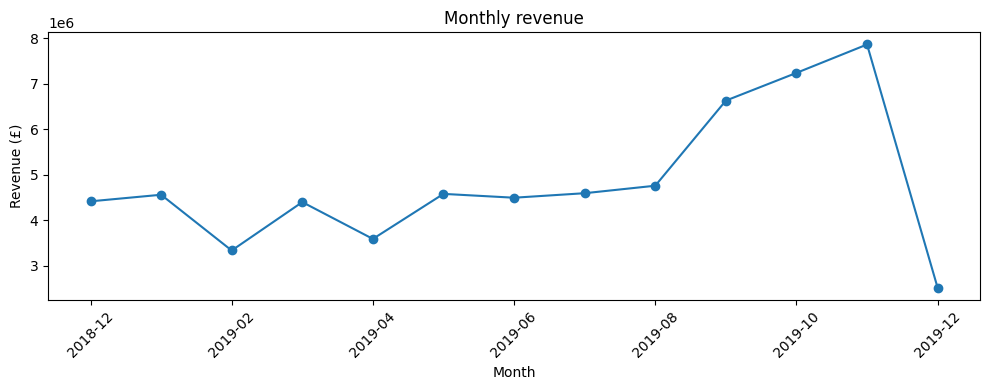

In [2]:
ax = monthly.plot(x="YearMonth", y="TotalValue", figsize=(10,4), marker="o", legend=False)
ax.set(title="Monthly revenue", ylabel="Revenue (£)", xlabel="Month")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## Top products by revenue
Here we aggregate transaction-level sales values at the product level.

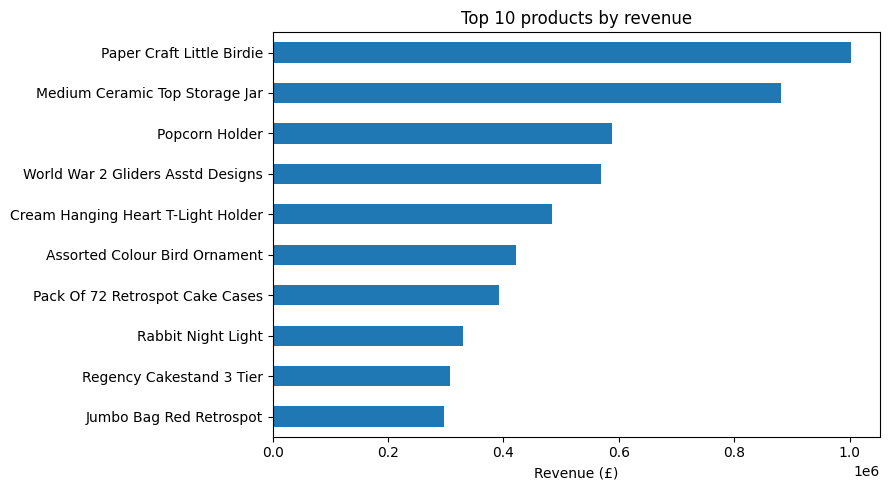

In [3]:
top = products.head(10).iloc[::-1]
ax = top.plot.barh(x="ProductName",y="TotalValue",figsize=(9,5),legend=False)
ax.set(title="Top 10 products by revenue",xlabel="Revenue (£)",ylabel="")
plt.tight_layout();plt.show()

## Geographic revenue
Revenue is largely concentrated in the retailer’s home market.

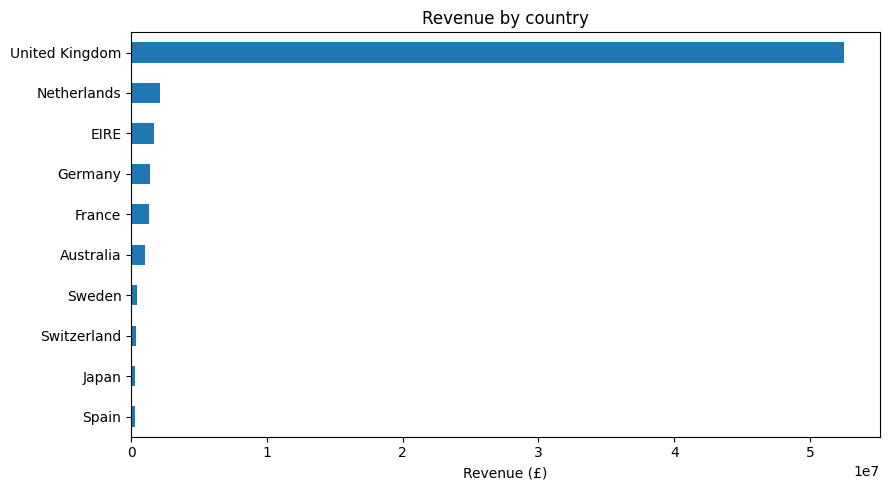

In [4]:
ax = countries.head(10).iloc[::-1].plot.barh(x="Country",y="TotalValue",figsize=(9,5),legend=False)
ax.set(title="Revenue by country",xlabel="Revenue (£)",ylabel="")
plt.tight_layout();plt.show()

## Revenue-quantile customer tiers (original notebook method)
These tiers are based on customer revenue percentiles, **not** on three-dimensional RFM K-means clustering.

In [5]:
revenue_tiers

,RevenueSegment,Customers,MeanRevenue,MeanTransactions
0,High Value,1180,41524.421593,9.750000
1,Low Value,1180,952.804788,1.361864
2,Medium Value,2358,5446.465314,2.831637


## RFM K-means — separately developed extension
Run `python src/rfm_clustering_extension.py` from the repository root after obtaining the original dataset. The generated aggregated cluster summary is included for inspection. Its numbers are **not** the same as those reported in the submitted thesis.

In [6]:
pd.read_csv(exports / "rfm_cluster_summary_EXTENSION.csv")

,Cluster,Customers,MeanRecencyDays,MeanFrequency,MeanMonetaryGBP
0,0,969,20.176471,2.270382,3674.565697
1,1,1409,203.198013,1.226402,1725.797452
2,2,932,15.549356,12.107296,43338.148090
3,3,1408,97.487926,3.250710,11777.297976


For the complete research report, see [`docs/Andre_Kurniawan_MSc_Thesis_2026.pdf`](../docs/Andre_Kurniawan_MSc_Thesis_2026.pdf), or consult the repository README for limitations and how to reproduce the Python analysis.